In [1]:
import nltk
import numpy as np
import pandas as pd
import string
import matplotlib.pyplot as plt

from nltk.stem import PorterStemmer
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    adjusted_mutual_info_score
)

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score


In [3]:
df = pd.read_csv('laptop_scenarios_story_text.csv')

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.head()

Shape: (19545, 6)

Columns: ['user_profile', 'budget_class', 'price_tier', 'story_text', 'upgrade_first', 'gain_class']


,user_profile,budget_class,price_tier,story_text,upgrade_first,gain_class
0,student,low,high,My main problem with this Apple Ultrabook is s...,Storage,Low
1,student,medium,high,"For anyone curious, this Apple Ultrabook has b...",Storage,Low
2,student,high,high,I would describe my Apple Ultrabook like this:...,Storage,Low
3,office,low,high,My take on this Apple Ultrabook is that it loo...,Storage,Low
4,office,medium,high,Current machine note: I am using an Apple Ultr...,Storage,Low


In [4]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def preprocess(text):
    tokens = nltk.word_tokenize(str(text))           # tokenisation
    tokens = [w.lower() for w in tokens]              # lowercasing
    tokens = [w for w in tokens if w not in stop_words]   # stop words
    tokens = [w for w in tokens if w not in string.punctuation]  # punctuation
    tokens = [stemmer.stem(w) for w in tokens]        # stemming
    return ' '.join(tokens)

df['clean_story'] = df['story_text'].apply(preprocess)

print("Shape after preprocessing:", df.shape)
df[['story_text', 'clean_story']].head(3)

Shape after preprocessing: (19545, 7)


,story_text,clean_story
0,My main problem with this Apple Ultrabook is s...,main problem appl ultrabook simpl student keep...
1,"For anyone curious, this Apple Ultrabook has b...",anyon curiou appl ultrabook machin student use...
2,I would describe my Apple Ultrabook like this:...,would describ appl ultrabook like look capabl ...


In [5]:
vectorizer = TfidfVectorizer(max_features=3500)
tfidf_matrix = vectorizer.fit_transform(df['clean_story'])

print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")
print(f"Sample feature names: {vectorizer.get_feature_names_out()[:20]}")
pd.DataFrame(tfidf_matrix.toarray(), columns=vectorizer.get_feature_names_out()).head()

TF-IDF matrix shape: (19545, 603)
Sample feature names: ['00kg' '02kg' '03kg' '04kg' '05kg' '06kg' '07kg' '08kg' '09kg' '0ghz'
 '10' '1024gb' '10kg' '11' '11kg' '12' '128gb' '12gb' '12kg' '13']


,00kg,02kg,03kg,04kg,05kg,06kg,07kg,08kg,09kg,0ghz,...,workabl,workflow,workload,workstat,would,write,wrong,xeon,xiaomi,yet
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.128594,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.120727,0.120629,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0


In [6]:
# Standardise
scaler = StandardScaler()
X_scaled = scaler.fit_transform(tfidf_matrix.toarray())

# PCA for clustering
pca = PCA(n_components=0.65, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"PCA components retained: {X_pca.shape[1]}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_):.4f}")

# PCA for 2D visualisation
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X_scaled)
print(f"\n2D PCA shape for visualisation: {X_2d.shape}")

PCA components retained: 74
Total variance explained: 0.6510

2D PCA shape for visualisation: (19545, 2)


In [7]:
metrics_dict = {
    "Model_Name": [],
    "ARI": [],
    "AMI": [],
    "Silhouette": [],
    "Calinski-Harabasz": [],
    "Davies-Bouldin": []
}

# **K-means**

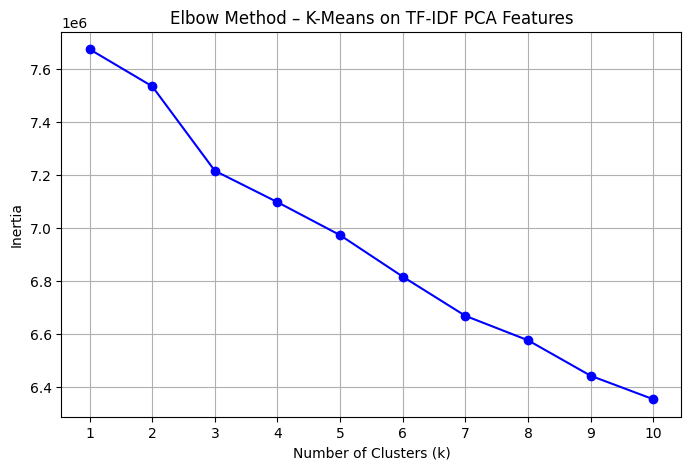

In [8]:
inertia = []
K = range(1, 11)

for k in K:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_pca)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method – K-Means on TF-IDF PCA Features')
plt.xticks(K)
plt.grid(True)
plt.show()

In [9]:
true_labels=df['gain_class']

KMeans Random k=3
ARI: 0.15906406540615173
AMI: 0.18381749843159517
Silhouette: 0.03736597102991965
Calinski-Harabasz: 704.282577965172
Davies-Bouldin: 4.370784558933047


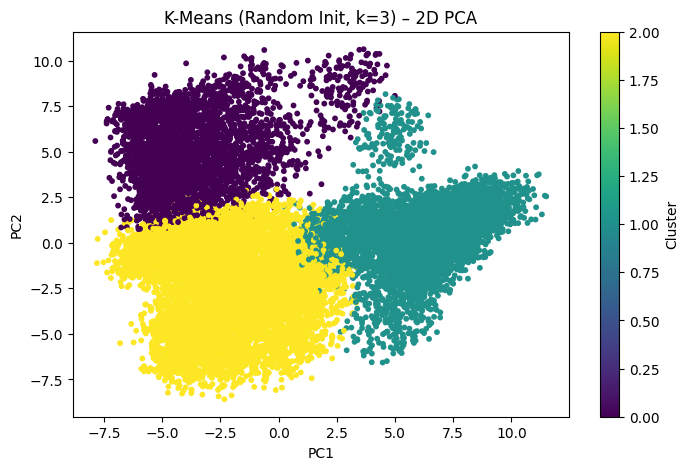

In [10]:
df_km_random = df.copy()

km_random = KMeans(n_clusters=3, init='random', random_state=42)
df_km_random['Cluster_KM_random'] = km_random.fit_predict(X_pca)

ari_km_random = adjusted_rand_score(true_labels, df_km_random['Cluster_KM_random'])
ami_km_random = adjusted_mutual_info_score(true_labels, df_km_random['Cluster_KM_random'])
sil_km_random = silhouette_score(X_pca, df_km_random['Cluster_KM_random'])
ch_km_random  = calinski_harabasz_score(X_pca, df_km_random['Cluster_KM_random'])
db_km_random  = davies_bouldin_score(X_pca, df_km_random['Cluster_KM_random'])

metrics_dict['ARI'].append(ari_km_random)
metrics_dict['AMI'].append(ami_km_random)
metrics_dict['Model_Name'].append('KMeans_random_k3')
metrics_dict['Silhouette'].append(sil_km_random)
metrics_dict['Calinski-Harabasz'].append(ch_km_random)
metrics_dict['Davies-Bouldin'].append(db_km_random)

print("KMeans Random k=3")
print("ARI:", ari_km_random)
print("AMI:", ami_km_random)
print("Silhouette:", sil_km_random)
print("Calinski-Harabasz:", ch_km_random)
print("Davies-Bouldin:", db_km_random)

plt.figure(figsize=(8, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df_km_random['Cluster_KM_random'], cmap='viridis', s=10)
plt.title('K-Means (Random Init, k=3) – 2D PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster')
plt.show()

KMeans++ k=3
ARI: 0.17504941348579128
AMI: 0.20298288620004082
Silhouette: 0.04781130904435601
Calinski-Harabasz: 620.8550877646769
Davies-Bouldin: 4.052269429941522


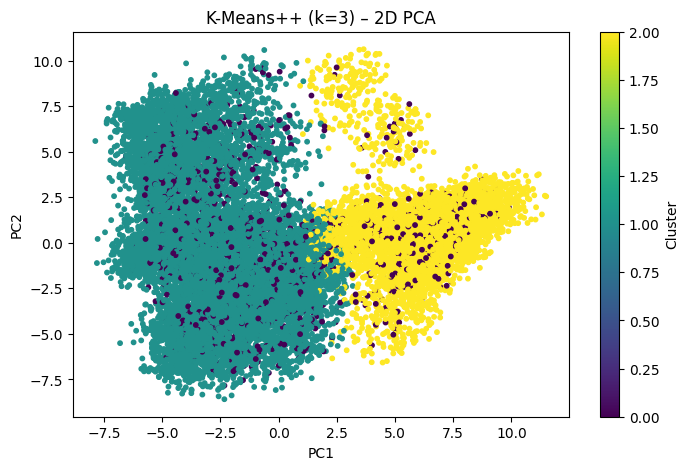

In [11]:
df_km_pp = df.copy()

km_pp = KMeans(n_clusters=3, init='k-means++', random_state=42)
df_km_pp['Cluster_KMpp'] = km_pp.fit_predict(X_pca)

true_labels = df['gain_class']


ari_km_pp = adjusted_rand_score(true_labels, df_km_pp['Cluster_KMpp'])
ami_km_pp = adjusted_mutual_info_score(true_labels, df_km_pp['Cluster_KMpp'])
sil_km_pp = silhouette_score(X_pca, df_km_pp['Cluster_KMpp'])
ch_km_pp  = calinski_harabasz_score(X_pca, df_km_pp['Cluster_KMpp'])
db_km_pp  = davies_bouldin_score(X_pca, df_km_pp['Cluster_KMpp'])

metrics_dict['Model_Name'].append('KMeans_pp_k3')
metrics_dict['Silhouette'].append(sil_km_pp)
metrics_dict['Calinski-Harabasz'].append(ch_km_pp)
metrics_dict['Davies-Bouldin'].append(db_km_pp)
metrics_dict['ARI'].append(ari_km_pp)
metrics_dict['AMI'].append(ami_km_pp)

print("KMeans++ k=3")
print("ARI:", ari_km_pp)
print("AMI:", ami_km_pp)
print("Silhouette:", sil_km_pp)
print("Calinski-Harabasz:", ch_km_pp)
print("Davies-Bouldin:", db_km_pp)

plt.figure(figsize=(8, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df_km_pp['Cluster_KMpp'], cmap='viridis', s=10)
plt.title('K-Means++ (k=3) – 2D PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster')
plt.show()

KMeans++ k=4
ARI: 0.1433611476217441
AMI: 0.19181080727803976
Silhouette: 0.04996678965895549
Calinski-Harabasz: 529.4068148805683
Davies-Bouldin: 3.849689913044825


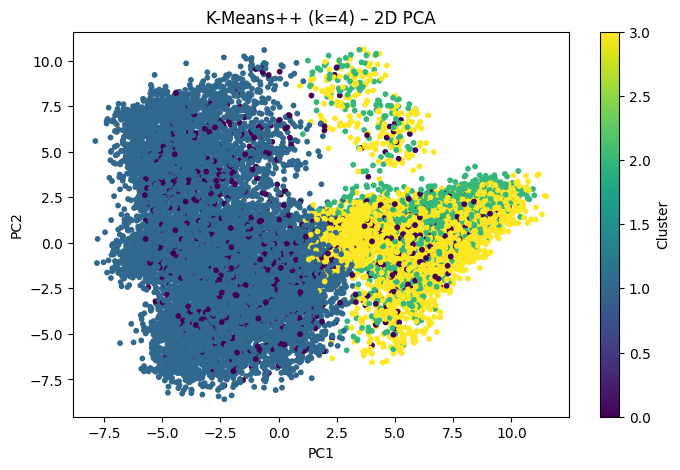

In [12]:
df_km_pp4 = df.copy()

km_pp4 = KMeans(n_clusters=4, init='k-means++', random_state=42)
df_km_pp4['Cluster_KMpp4'] = km_pp4.fit_predict(X_pca)

ari_km_pp4 = adjusted_rand_score(true_labels, df_km_pp4['Cluster_KMpp4'])
ami_km_pp4 = adjusted_mutual_info_score(true_labels, df_km_pp4['Cluster_KMpp4'])
sil_km_pp4 = silhouette_score(X_pca, df_km_pp4['Cluster_KMpp4'])
ch_km_pp4  = calinski_harabasz_score(X_pca, df_km_pp4['Cluster_KMpp4'])
db_km_pp4  = davies_bouldin_score(X_pca, df_km_pp4['Cluster_KMpp4'])

metrics_dict['Model_Name'].append('KMeans_pp_k4')
metrics_dict['Silhouette'].append(sil_km_pp4)
metrics_dict['Calinski-Harabasz'].append(ch_km_pp4)
metrics_dict['Davies-Bouldin'].append(db_km_pp4)
metrics_dict['ARI'].append(ari_km_pp4)
metrics_dict['AMI'].append(ami_km_pp4)


print("KMeans++ k=4")
print("ARI:", ari_km_pp4)
print("AMI:", ami_km_pp4)
print("Silhouette:", sil_km_pp4)
print("Calinski-Harabasz:", ch_km_pp4)
print("Davies-Bouldin:", db_km_pp4)


plt.figure(figsize=(8, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df_km_pp4['Cluster_KMpp4'], cmap='viridis', s=10)
plt.title('K-Means++ (k=4) – 2D PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster')
plt.show()

# **Agglomerative Clustering**

In [13]:
from scipy.cluster.hierarchy import dendrogram, linkage

sample_size = 100
X_dendro = X_pca[:sample_size]

In [14]:
from sklearn.cluster import AgglomerativeClustering

df_agg_ward = df.copy()

agg_ward = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_agg_ward['Cluster_Agg_Ward'] = agg_ward.fit_predict(X_pca)

ari_agg_ward = adjusted_rand_score(true_labels, df_agg_ward['Cluster_Agg_Ward'])
ami_agg_ward = adjusted_mutual_info_score(true_labels, df_agg_ward['Cluster_Agg_Ward'])
sil_agg_ward = silhouette_score(X_pca, df_agg_ward['Cluster_Agg_Ward'])
ch_agg_ward  = calinski_harabasz_score(X_pca, df_agg_ward['Cluster_Agg_Ward'])
db_agg_ward  = davies_bouldin_score(X_pca, df_agg_ward['Cluster_Agg_Ward'])

metrics_dict['Model_Name'].append('Agglomerative_ward_k3')
metrics_dict['ARI'].append(ari_agg_ward)
metrics_dict['AMI'].append(ami_agg_ward)
metrics_dict['Silhouette'].append(sil_agg_ward)
metrics_dict['Calinski-Harabasz'].append(ch_agg_ward)
metrics_dict['Davies-Bouldin'].append(db_agg_ward)

print("Agglomerative Ward k=3")
print("ARI:", ari_agg_ward)
print("AMI:", ami_agg_ward)
print("Silhouette:", sil_agg_ward)
print("Calinski-Harabasz:", ch_agg_ward)
print("Davies-Bouldin:", db_agg_ward)

Agglomerative Ward k=3
ARI: 0.04043465320316073
AMI: 0.04267475727868416
Silhouette: 0.023110293245478378
Calinski-Harabasz: 290.08813795898993
Davies-Bouldin: 6.302798020539908


In [15]:
import scipy.cluster.hierarchy as shc

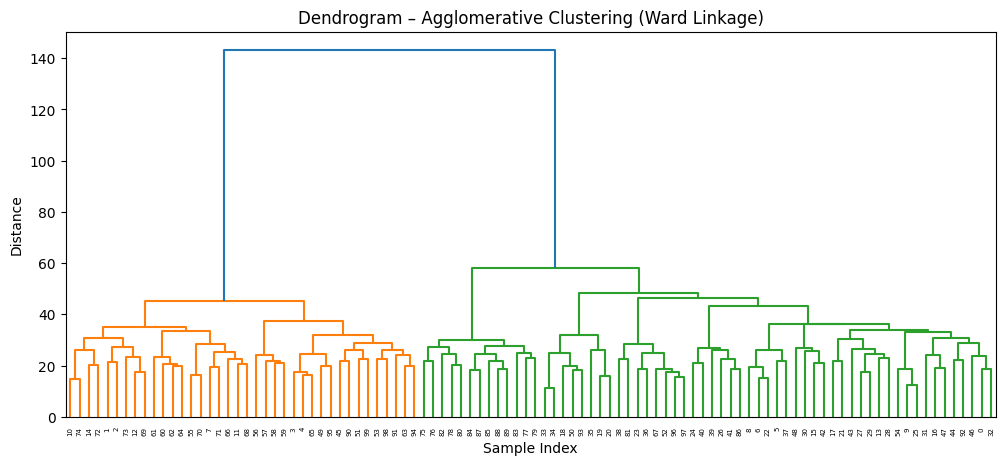

In [16]:
plt.figure(figsize=(12, 5))
dend = shc.dendrogram(shc.linkage(X_pca[:100], method='ward'))
plt.title('Dendrogram – Agglomerative Clustering (Ward Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

In [17]:
#Complete - Agglomerative
df_agg_comp = df.copy()

agg_comp = AgglomerativeClustering(n_clusters=3, linkage='complete')
df_agg_comp['Cluster_Agg_Complete'] = agg_comp.fit_predict(X_pca)

ari_agg_comp = adjusted_rand_score(true_labels, df_agg_comp['Cluster_Agg_Complete'])
ami_agg_comp = adjusted_mutual_info_score(true_labels, df_agg_comp['Cluster_Agg_Complete'])
sil_agg_comp = silhouette_score(X_pca, df_agg_comp['Cluster_Agg_Complete'])
ch_agg_comp  = calinski_harabasz_score(X_pca, df_agg_comp['Cluster_Agg_Complete'])
db_agg_comp  = davies_bouldin_score(X_pca, df_agg_comp['Cluster_Agg_Complete'])

metrics_dict['Model_Name'].append('Agglomerative_complete_k3')
metrics_dict['ARI'].append(ari_agg_comp)
metrics_dict['AMI'].append(ami_agg_comp)
metrics_dict['Silhouette'].append(sil_agg_comp)
metrics_dict['Calinski-Harabasz'].append(ch_agg_comp)
metrics_dict['Davies-Bouldin'].append(db_agg_comp)

print("Agglomerative Complete k=3")
print("ARI:", ari_agg_comp)
print("AMI:", ami_agg_comp)
print("Silhouette:", sil_agg_comp)
print("Calinski-Harabasz:", ch_agg_comp)
print("Davies-Bouldin:", db_agg_comp)

Agglomerative Complete k=3
ARI: -0.0011888179387532867
AMI: 0.002802649714719305
Silhouette: 0.18652692816034036
Calinski-Harabasz: 178.66335769621165
Davies-Bouldin: 1.723685848255273


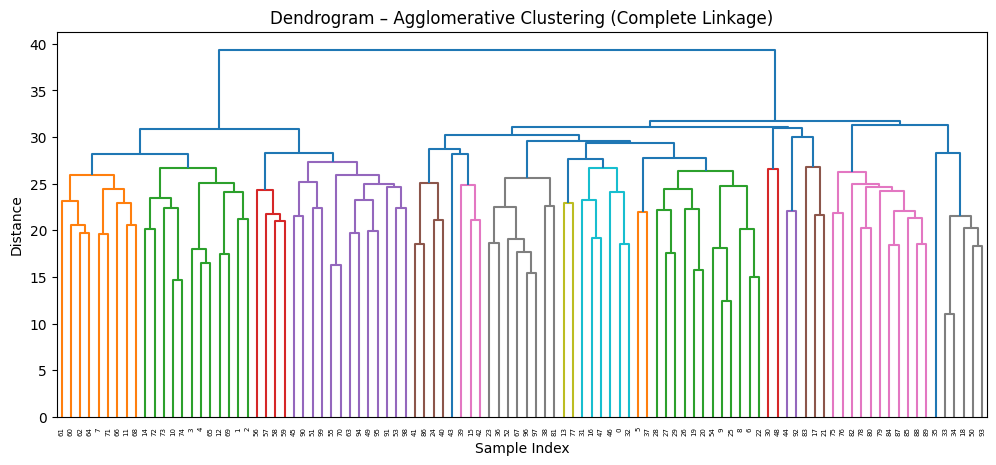

In [18]:
linked_complete = linkage(X_dendro, method='complete')

plt.figure(figsize=(12, 5))
dendrogram(linked_complete)
plt.title('Dendrogram – Agglomerative Clustering (Complete Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

In [19]:
#Average - Agglomerative
df_agg_avg = df.copy()

agg_avg = AgglomerativeClustering(n_clusters=3, linkage='average')
df_agg_avg['Cluster_Agg_Average'] = agg_avg.fit_predict(X_pca)

ari_agg_avg = adjusted_rand_score(true_labels, df_agg_avg['Cluster_Agg_Average'])
ami_agg_avg = adjusted_mutual_info_score(true_labels, df_agg_avg['Cluster_Agg_Average'])
sil_agg_avg = silhouette_score(X_pca, df_agg_avg['Cluster_Agg_Average'])
ch_agg_avg  = calinski_harabasz_score(X_pca, df_agg_avg['Cluster_Agg_Average'])
db_agg_avg  = davies_bouldin_score(X_pca, df_agg_avg['Cluster_Agg_Average'])

metrics_dict['Model_Name'].append('Agglomerative_average_k3')
metrics_dict['ARI'].append(ari_agg_avg)
metrics_dict['AMI'].append(ami_agg_avg)
metrics_dict['Silhouette'].append(sil_agg_avg)
metrics_dict['Calinski-Harabasz'].append(ch_agg_avg)
metrics_dict['Davies-Bouldin'].append(db_agg_avg)

print("Agglomerative Average k=3")
print("ARI:", ari_agg_avg)
print("AMI:", ami_agg_avg)
print("Silhouette:", sil_agg_avg)
print("Calinski-Harabasz:", ch_agg_avg)
print("Davies-Bouldin:", db_agg_avg)

Agglomerative Average k=3
ARI: -0.0008206508185164727
AMI: 0.0023205445868742444
Silhouette: 0.2037489202978618
Calinski-Harabasz: 181.69801372195812
Davies-Bouldin: 1.6420835966127596


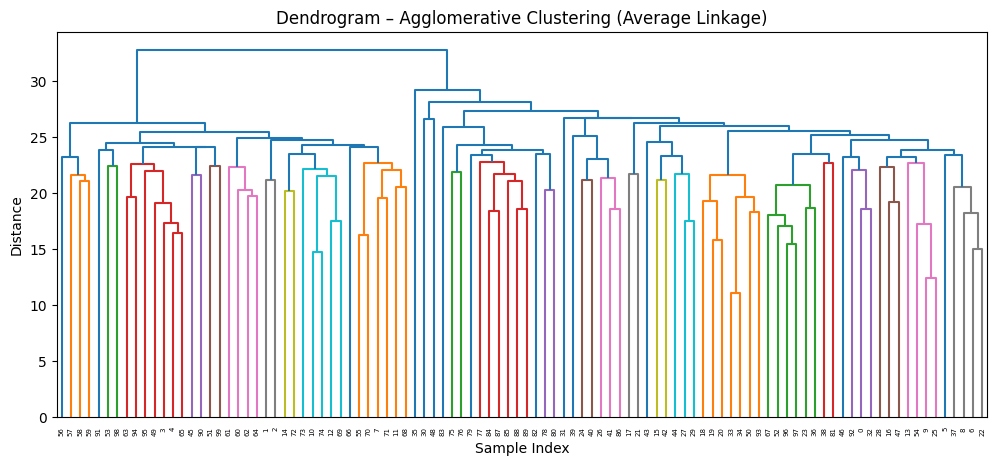

In [20]:
linked_average = linkage(X_dendro, method='average')

plt.figure(figsize=(12, 5))
dendrogram(linked_average)
plt.title('Dendrogram – Agglomerative Clustering (Average Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

Agglomerative Single k=3
ARI: -1.4258364988907729e-05
AMI: -1.3989855493165318e-05
Silhouette: 0.17552152930743048
Calinski-Harabasz: 2.1165694541861746
Davies-Bouldin: 0.6892446124011394


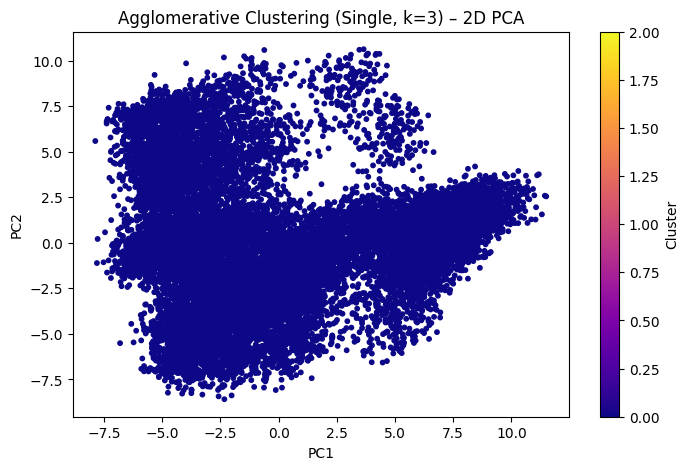

In [21]:
#Sinlge - Agglomerative
df_agg_single = df.copy()

agg_single = AgglomerativeClustering(n_clusters=3, linkage='single')
df_agg_single['Cluster_Agg_Single'] = agg_single.fit_predict(X_pca)

ari_agg_single = adjusted_rand_score(true_labels, df_agg_single['Cluster_Agg_Single'])
ami_agg_single = adjusted_mutual_info_score(true_labels, df_agg_single['Cluster_Agg_Single'])
sil_agg_single = silhouette_score(X_pca, df_agg_single['Cluster_Agg_Single'])
ch_agg_single  = calinski_harabasz_score(X_pca, df_agg_single['Cluster_Agg_Single'])
db_agg_single  = davies_bouldin_score(X_pca, df_agg_single['Cluster_Agg_Single'])

metrics_dict['Model_Name'].append('Agglomerative_single_k3')
metrics_dict['ARI'].append(ari_agg_single)
metrics_dict['AMI'].append(ami_agg_single)
metrics_dict['Silhouette'].append(sil_agg_single)
metrics_dict['Calinski-Harabasz'].append(ch_agg_single)
metrics_dict['Davies-Bouldin'].append(db_agg_single)

print("Agglomerative Single k=3")
print("ARI:", ari_agg_single)
print("AMI:", ami_agg_single)
print("Silhouette:", sil_agg_single)
print("Calinski-Harabasz:", ch_agg_single)
print("Davies-Bouldin:", db_agg_single)

plt.figure(figsize=(8, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df_agg_single['Cluster_Agg_Single'], cmap='plasma', s=10)
plt.title('Agglomerative Clustering (Single, k=3) – 2D PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster')
plt.show()

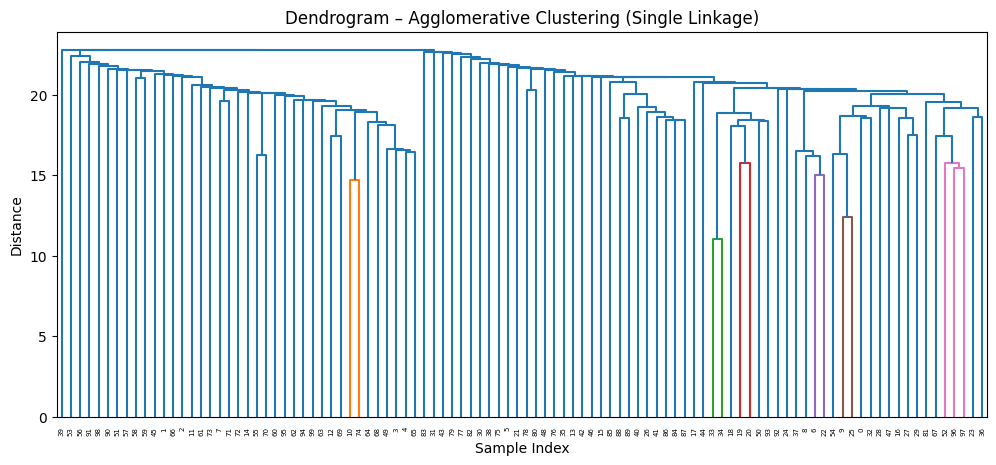

In [22]:
linked_single = linkage(X_dendro, method='single')

plt.figure(figsize=(12, 5))
dendrogram(linked_single)
plt.title('Dendrogram – Agglomerative Clustering (Single Linkage)')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

# **DBSCAN**

In [23]:
df_dbs1 = df.copy()

dbs1 = DBSCAN(eps=10, min_samples=5)
y_dbs1 = dbs1.fit_predict(X_pca)

df_dbs1['Cluster_DBSCAN1'] = y_dbs1

n_clusters_dbs1 = len(set(y_dbs1)) - (1 if -1 in y_dbs1 else 0)
n_noise_dbs1 = list(y_dbs1).count(-1)

ari_dbs1 = adjusted_rand_score(true_labels, y_dbs1)
ami_dbs1 = adjusted_mutual_info_score(true_labels, y_dbs1)

metrics_dict['Model_Name'].append('DBSCAN_eps10_m5')
metrics_dict['ARI'].append(ari_dbs1)
metrics_dict['AMI'].append(ami_dbs1)

if n_clusters_dbs1 > 1:
    sil_dbs1 = silhouette_score(X_pca, y_dbs1)
    ch_dbs1  = calinski_harabasz_score(X_pca, y_dbs1)
    db_dbs1  = davies_bouldin_score(X_pca, y_dbs1)
    metrics_dict['Silhouette'].append(sil_dbs1)
    metrics_dict['Calinski-Harabasz'].append(ch_dbs1)
    metrics_dict['Davies-Bouldin'].append(db_dbs1)
else:
    metrics_dict['Silhouette'].append('N/A – 0 clusters')
    metrics_dict['Calinski-Harabasz'].append('N/A – 0 clusters')
    metrics_dict['Davies-Bouldin'].append('N/A – 0 clusters')

print("DBSCAN Trial 1 (eps=10, min_samples=5)")
print("Clusters found:", n_clusters_dbs1)
print("Noise points:", n_noise_dbs1, "out of", len(df_dbs1), "total points")
print("ARI:", ari_dbs1)
print("AMI:", ami_dbs1)

DBSCAN Trial 1 (eps=10, min_samples=5)
Clusters found: 7
Noise points: 19499 out of 19545 total points
ARI: 0.0002960628681733222
AMI: 0.0025815235482685196


In [24]:
df_dbs2 = df.copy()

dbs2 = DBSCAN(eps=10, min_samples=3)
y_dbs2 = dbs2.fit_predict(X_pca)

df_dbs2['Cluster_DBSCAN2'] = y_dbs2

n_clusters_dbs2 = len(set(y_dbs2)) - (1 if -1 in y_dbs2 else 0)
n_noise_dbs2 = list(y_dbs2).count(-1)

ari_dbs2 = adjusted_rand_score(true_labels, y_dbs2)
ami_dbs2 = adjusted_mutual_info_score(true_labels, y_dbs2)

metrics_dict['Model_Name'].append('DBSCAN_eps10_m3')
metrics_dict['ARI'].append(ari_dbs2)
metrics_dict['AMI'].append(ami_dbs2)

if n_clusters_dbs2 > 1:
    sil_dbs2 = silhouette_score(X_pca, y_dbs2)
    ch_dbs2  = calinski_harabasz_score(X_pca, y_dbs2)
    db_dbs2  = davies_bouldin_score(X_pca, y_dbs2)
    metrics_dict['Silhouette'].append(sil_dbs2)
    metrics_dict['Calinski-Harabasz'].append(ch_dbs2)
    metrics_dict['Davies-Bouldin'].append(db_dbs2)
else:
    metrics_dict['Silhouette'].append('N/A – 0 clusters')
    metrics_dict['Calinski-Harabasz'].append('N/A – 0 clusters')
    metrics_dict['Davies-Bouldin'].append('N/A – 0 clusters')

print("DBSCAN Trial 2 (eps=10, min_samples=3)")
print("Clusters found:", n_clusters_dbs2)
print("Noise points:", n_noise_dbs2, "out of", len(df_dbs2), "total points")
print("ARI:", ari_dbs2)
print("AMI:", ami_dbs2)

DBSCAN Trial 2 (eps=10, min_samples=3)
Clusters found: 219
Noise points: 18788 out of 19545 total points
ARI: 0.0001306625797470696
AMI: 0.020164570901011543


In [25]:
df_dbs3 = df.copy()

dbs3 = DBSCAN(eps=7, min_samples=3)
y_dbs3 = dbs3.fit_predict(X_pca)

df_dbs3['Cluster_DBSCAN3'] = y_dbs3

n_clusters_dbs3 = len(set(y_dbs3)) - (1 if -1 in y_dbs3 else 0)
n_noise_dbs3 = list(y_dbs3).count(-1)

ari_dbs3 = adjusted_rand_score(true_labels, y_dbs3)
ami_dbs3 = adjusted_mutual_info_score(true_labels, y_dbs3)

metrics_dict['Model_Name'].append('DBSCAN_eps7_m3')
metrics_dict['ARI'].append(ari_dbs3)
metrics_dict['AMI'].append(ami_dbs3)

if n_clusters_dbs3 > 1:
    sil_dbs3 = silhouette_score(X_pca, y_dbs3)
    ch_dbs3  = calinski_harabasz_score(X_pca, y_dbs3)
    db_dbs3  = davies_bouldin_score(X_pca, y_dbs3)
    metrics_dict['Silhouette'].append(sil_dbs3)
    metrics_dict['Calinski-Harabasz'].append(ch_dbs3)
    metrics_dict['Davies-Bouldin'].append(db_dbs3)
else:
    metrics_dict['Silhouette'].append('N/A – 0 clusters')
    metrics_dict['Calinski-Harabasz'].append('N/A – 0 clusters')
    metrics_dict['Davies-Bouldin'].append('N/A – 0 clusters')

print("DBSCAN Trial 3 (eps=7, min_samples=3)")
print("Clusters found:", n_clusters_dbs3)
print("Noise points:", n_noise_dbs3, "out of", len(df_dbs3), "total points")
print("ARI:", ari_dbs3)
print("AMI:", ami_dbs3)

DBSCAN Trial 3 (eps=7, min_samples=3)
Clusters found: 9
Noise points: 19516 out of 19545 total points
ARI: 0.0001230192319031161
AMI: 0.0015650535200678643


In [26]:
metrics_df = pd.DataFrame(metrics_dict)
print(metrics_df.to_string(index=False))

               Model_Name       ARI       AMI  Silhouette  Calinski-Harabasz  Davies-Bouldin
         KMeans_random_k3  0.159064  0.183817    0.037366         704.282578        4.370785
             KMeans_pp_k3  0.175049  0.202983    0.047811         620.855088        4.052269
             KMeans_pp_k4  0.143361  0.191811    0.049967         529.406815        3.849690
    Agglomerative_ward_k3  0.040435  0.042675    0.023110         290.088138        6.302798
Agglomerative_complete_k3 -0.001189  0.002803    0.186527         178.663358        1.723686
 Agglomerative_average_k3 -0.000821  0.002321    0.203749         181.698014        1.642084
  Agglomerative_single_k3 -0.000014 -0.000014    0.175522           2.116569        0.689245
          DBSCAN_eps10_m5  0.000296  0.002582   -0.157100           4.531475        1.634295
          DBSCAN_eps10_m3  0.000131  0.020165   -0.309023           2.826807        1.447700
           DBSCAN_eps7_m3  0.000123  0.001565   -0.137577           2.

# **Cluster Persona Cards**

In [27]:
df['Cluster'] = df_km_pp['Cluster_KMpp']

feature_names = vectorizer.get_feature_names_out()
tfidf_array = tfidf_matrix.toarray()

def get_top_terms(cluster_id, top_n=10):
    indices = df[df['Cluster'] == cluster_id].index
    cluster_tfidf = tfidf_array[indices].mean(axis=0)
    top_indices = cluster_tfidf.argsort()[::-1][:top_n]
    return [feature_names[i] for i in top_indices]

for c in sorted(df['Cluster'].unique()):
    print(f"Cluster {c} top terms: {get_top_terms(c)}")

Cluster 0 top terms: ['care', 'strict', 'one', 'mean', 'lot', 'hurt', 'decis', 'issu', 'make', 'intel']
Cluster 1 top terms: ['graphic', 'feel', 'intel', 'integr', 'machin', '4gb', 'use', '256gb', 'ram', '8gb']
Cluster 2 top terms: ['offic', 'still', 'work', 'want', 'feel', 'rather', 'meet', 'mostli', 'comfort', 'notic']


In [28]:
for c in sorted(df['Cluster'].unique()):
    cluster_data = df[df['Cluster'] == c]
    print(f"\n--- Cluster {c} ---")
    print("Size:", len(cluster_data))
    print("User Profile:\n", cluster_data['user_profile'].value_counts().head(3))
    print("Upgrade First:\n", cluster_data['upgrade_first'].value_counts().head(3))
    print("Budget Class:\n", cluster_data['budget_class'].value_counts().head(3))


--- Cluster 0 ---
Size: 1656
User Profile:
 user_profile
office      354
designer    333
gamer       326
Name: count, dtype: int64
Upgrade First:
 upgrade_first
RAM                  831
No Upgrade Needed    502
Storage              293
Name: count, dtype: int64
Budget Class:
 budget_class
low    1656
Name: count, dtype: int64

--- Cluster 1 ---
Size: 12440
User Profile:
 user_profile
gamer         3354
designer      3277
programmer    3159
Name: count, dtype: int64
Upgrade First:
 upgrade_first
RAM        6766
Storage    2339
GPU        2142
Name: count, dtype: int64
Budget Class:
 budget_class
high      4553
medium    4480
low       3407
Name: count, dtype: int64

--- Cluster 2 ---
Size: 5449
User Profile:
 user_profile
office        3022
student       1475
programmer     424
Name: count, dtype: int64
Upgrade First:
 upgrade_first
No Upgrade Needed    3964
Storage               892
RAM                   593
Name: count, dtype: int64
Budget Class:
 budget_class
medium    2035
high    

In [36]:
persona_cards = {
    0: {
        "label": "Low-Budget Frustrated Users",
        "top_terms": get_top_terms(0),
        "dominant_profile": "office",
        "upgrade_tendency": "RAM",
    },
    1: {
        "label": "Performance-Driven Power Users",
        "top_terms": get_top_terms(1),
        "dominant_profile": "gamer",
        "upgrade_tendency": "RAM",
    },
    2: {
        "label": "Satisfied Office and Student Users",
        "top_terms": get_top_terms(2),
        "dominant_profile": "office",
        "upgrade_tendency": "No Upgrade Needed",
    }
}

# Print Persona Cards
print(f"  CLUSTER PERSONA CARDS")
print("-" * 10)

for cluster_id, card in persona_cards.items():
    print(f"  Cluster ID        : {cluster_id}")
    print(f"  Cluster Label     : {card['label']}")
    print(f"  Top Terms         : {', '.join(card['top_terms'])}")
    print(f"  Dominant Profile  : {card['dominant_profile']}")
    print(f"  Upgrade Tendency  : {card['upgrade_tendency']}")
    print("-" * 10)


  CLUSTER PERSONA CARDS
----------
  Cluster ID        : 0
  Cluster Label     : Low-Budget Frustrated Users
  Top Terms         : care, strict, one, mean, lot, hurt, decis, issu, make, intel
  Dominant Profile  : office
  Upgrade Tendency  : RAM
----------
  Cluster ID        : 1
  Cluster Label     : Performance-Driven Power Users
  Top Terms         : graphic, feel, intel, integr, machin, 4gb, use, 256gb, ram, 8gb
  Dominant Profile  : gamer
  Upgrade Tendency  : RAM
----------
  Cluster ID        : 2
  Cluster Label     : Satisfied Office and Student Users
  Top Terms         : offic, still, work, want, feel, rather, meet, mostli, comfort, notic
  Dominant Profile  : office
  Upgrade Tendency  : No Upgrade Needed
----------
